# 15 Pre-Class Assignment: Singular Value Decomposition

## Goals for today's pre-class assignment 

</p>

1. [Video On Singular Value Decomposition](#Video_On_Signular_Value_Decomposition)
1. [Diagonalizing a Square Matrix](#Diag)
1. [Singular Value Decomposition](#SVD)

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import sympy as sym
sym.init_printing()

---
<a name="Video_On_Signular_Value_Decomposition"></a>

# 1. Video On Signular Value Decomposition

Calculating the eigenvaluse and eigenvectors of a matrix requires that the matrix is square ($n \times n$). Think of SVD as a way to get similar information from a non-square matrix.

This video is a little longer than most videos.  I recommend reading the questions first and then watching the video and following along with the provided code examples.

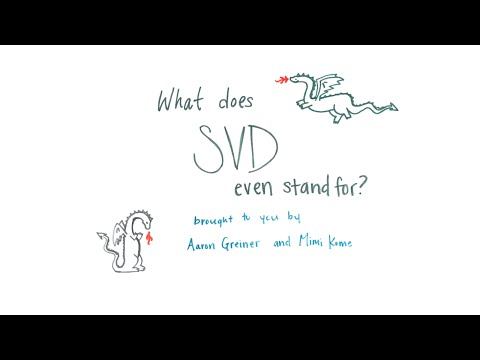

In [2]:
from IPython.display import YouTubeVideo
YouTubeVideo("EfZsEFhHcNM",width=640,height=360)

---
<a name="Diag"></a>

## 2. Diagonalizing a Square Matrix

As we saw in previous assignments, a square matrix $n\times n$, whose eigenvectors form a basis of $\mathbb R^n$ is diagonalizable.
Consider the following matrix provided in the above video (~1:50 into the video)

In [3]:
A = np.matrix([[1,1,3], [-3, -5, -3], [3, 3, 1]])
sym.Matrix(A)

⎡1   1   3 ⎤
⎢          ⎥
⎢-3  -5  -3⎥
⎢          ⎥
⎣3   3   1 ⎦

&#9989; <font color=red>**DO THIS:**</font> Calculate the Eigenvalues and Eigenvectors for the above matrix $A$. name the eigenvalues (vals) and the eigenvectors (vecs)

In [4]:
##Put your code here
vals, vecs = np.linalg.eig(A)

The following code sorts the eigenvectors based on the ordering of the eigenvalues. It does this using the argsort algorithm which puts the values in ascending order.  The ```[::-1]``` notation reverses the order of the indexes.  We will put the sorted vectors into a matrix called $P$

In [5]:
idx = vals.argsort()[::-1]   
vals = vals[idx]
vecs = vecs[:,idx]


print(idx)
V = vecs
sym.Matrix(V)
print(V)
P = vecs
sym.Matrix(P)

[0 2 1]
[[-7.17666340e-01 -7.07106781e-01  3.07751722e-01]
 [ 4.92420057e-01 -6.10622664e-16  6.72788554e-01]
 [-4.92420057e-01  7.07106781e-01 -6.72788554e-01]]


⎡-0.717666339515337   -0.707106781186547    0.307751722477118 ⎤
⎢                                                             ⎥
⎢0.492420057027868   -6.10622663543836e-16  0.672788554195286 ⎥
⎢                                                             ⎥
⎣-0.492420057027868    0.707106781186548    -0.672788554195286⎦

The following code generates a matrix of the same size as $A$ and puts the eigenvalues on the diagonals. 

In [6]:
D = np.zeros(A.shape)
for i in range(len(vals)):
    D[i,i] = vals[i]
sym.Matrix(D)

⎡2.37228132326901   0            0        ⎤
⎢                                         ⎥
⎢       0          -2.0          0        ⎥
⎢                                         ⎥
⎣       0           0    -3.37228132326901⎦

&#9989; <font color=red>**DO THIS:**</font> Show that $A=PDP^{-1}$

In [7]:
#Put your answer here
P_inv = np.linalg.inv(P)
print(A)
print(P*D*P_inv)

[[ 1  1  3]
 [-3 -5 -3]
 [ 3  3  1]]
[[ 1.  1.  3.]
 [-3. -5. -3.]
 [ 3.  3.  1.]]


In [8]:
###Answer###

P*D*np.linalg.inv(P)-A
###Answer###

matrix([[ 6.66133815e-16,  6.66133815e-16, -2.22044605e-15],
        [-8.88178420e-16, -8.88178420e-16,  0.00000000e+00],
        [ 1.77635684e-15,  4.44089210e-16,  2.22044605e-16]])

&#9989; <font color=red>**DO THIS:**</font> Show that $A^{10}=PD^{10}P^{-1}$. I.e. multiply A by itself 10 times and then taking $\sigma^{10}$ for each of the eigenvalues in the diagonal of $D$.

In [9]:
print(A**10)
print(P*D**10*np.linalg.inv(P))


[[  49735  112969   48711]
 [  96387  242509   96387]
 [ -96387 -241485  -95363]]
[[  49735.  112969.   48711.]
 [  96387.  242509.   96387.]
 [ -96387. -241485.  -95363.]]


&#9989; <font color=red>**QUESTION 1:**</font> What is the estimated complexity of multiplying an arbitrary $n\times n$ matrix by itself $m$ times? (Hint: both $m$ and $n$ should be included in your Big-O notation answer). 

Complexity is O(mn^3).


### Note:
Diagonalization of an $n\times n$ matrix takes $O(n^3)$ operations.

&#9989; <font color=red>**QUESTION 2:**</font> What is the estimated complexity (Big-O) of multiplying a diagonlized $n \times n$ matrix by itself $m$ times? i.e. you already have $A=PDP^{-1}$ calculated what does it cost to calculate $A^m$?

Complexity is O(n^2).

### Inverse of an orthonormal matrix $U$ is $U^\top$
    
Caluclate the $P$ matrix for the following matrix $A$ such that $A=PDP^{-1}$

In [10]:
A = np.matrix([[6,-2,-1],[-2,6,-1], [-1,-1,5]])
sym.Matrix(A)

⎡6   -2  -1⎤
⎢          ⎥
⎢-2  6   -1⎥
⎢          ⎥
⎣-1  -1  5 ⎦

&#9989; <font color=red>**DO THIS:**</font> Check the columns of $P$. Are they orthogonal?

No.

&#9989; <font color=red>**DO THIS:**</font> Show that in this special case (Where $A$ is symmetric) $A=PDP^\top$ with a special $P$.

P = [v1 | v2 | ... | vn]

D = diag(λ1, λ2, ..., λn)

P^T P = [v1^T; v2^T; ...; vn^T][v1 | v2 | ... | vn] = I

A = PDP^T

&#9989; <font color=red>**QUESTION 3:**</font> What do you need to do to invert an arbitrary $n \times n$ matrix?

Check if the matrix is invertible or not. If the determinant of the matrix is zero, then it is not invertible.

If the matrix is invertible, then we can find its inverse by using the following formula:

A^-1 = (1/det(A)) * adj(A)

where A^-1 is the inverse of matrix A, det(A) is the determinant of matrix A, and adj(A) is the adjugate or classical adjoint of matrix A.

To calculate the adjugate of matrix A, we need to find the matrix of cofactors of A, which is obtained by replacing each element of A with its corresponding cofactor.

The cofactor of each element in A is defined as (-1)^(i+j) times the determinant of the matrix obtained by deleting the i-th row and j-th column of A.

Once we have the matrix of cofactors, we need to take its transpose to get the adjugate of A.

Finally, we can use the above formula to find the inverse of A.



&#9989; <font color=red>**QUESTION 4:**</font> What do you need to do to invert a $n \times n$ **orthonormal** matrix?

To invert an 𝑛×𝑛 orthonormal matrix, you can simply take its transpose, because the transpose of an orthonormal matrix is its inverse. This is because the columns of an orthonormal matrix are all unit vectors and orthogonal to each other, so the dot product of any two columns is 0. Therefore, the dot product of a column with its corresponding row in the transpose is 1 (since the diagonal entries of an orthonormal matrix are all 1) and 0 for all other entries, which is the definition of the identity matrix.

So, if 𝑄 is an 𝑛×𝑛 orthonormal matrix, its inverse is simply 𝑄^T .






---
<a name="SVD"></a>

## 3. Singular Value Decomposition (SVD) 

SVD is not restricted to diagonalizable matrices, for example it can be applied to square non-diagonalizable matrices, as well as to non-square matrices.

Now consider the non-square $n \times m$ matrix $A$

In [11]:
A = np.matrix([[4, 11, 14], [8, 7, -2]])

sym.Matrix(A)

⎡4  11  14⎤
⎢         ⎥
⎣8  7   -2⎦

The following code calculates $A^\top A=VDV^\top$:

In [12]:
sym.Matrix(A.T*A)

⎡80   100  40 ⎤
⎢             ⎥
⎢100  170  140⎥
⎢             ⎥
⎣40   140  200⎦

In [25]:
eigvals, eigvec = np.linalg.eig(A.T*A)
idx = eigvals.argsort()[::-1]   
eigvals = eigvals[idx]
eigvec = eigvec[:,idx]

U = eigvec
sym.Matrix(U*D*V.T)

⎡ -2.124093774423    1.58152088217934   0.666666666666667 ⎤
⎢                                                         ⎥
⎢1.58152088217934   -0.666666666666666   2.24818754884601 ⎥
⎢                                                         ⎥
⎣0.666666666666667   2.24818754884601   -0.209239558910329⎦

&#9989; <font color=red>**DO THIS:**</font>  Calculate $AA^\top=UDU^\top$:

In [28]:
#Put your answer here
print(sym.Matrix(A*A.T))
eigvals, eigvec = np.linalg.eig(A*A.T)
idx = eigvals.argsort()[::-1]   
eigvals = eigvals[idx]
eigvec = eigvec[:,idx]

U = eigvec
sym.Matrix(U)


Matrix([[333, 81], [81, 117]])


⎡0.948683298050514  -0.316227766016838⎤
⎢                                     ⎥
⎣0.316227766016838  0.948683298050514 ⎦

The following code calculates $\Sigma$ by putting the singular values on the diagonal of an $n \times m$ zero matrix: 

In [31]:
np.sqrt(np.abs(eigvals))*np.identity(1)

E = np.zeros(A.shape)

for i in range(len(eigvals)):
    E[i,i] = np.sqrt(eigvals[i])
    
sym.Matrix(E)

⎡18.9736659610103         0          0⎤
⎢                                     ⎥
⎣       0          9.48683298050514  0⎦

&#9989; <font color=red>**DO THIS:**</font>  Verify that $A=U \Sigma V^\top$ or $A=-U\Sigma V^\top$. 

**Note:** $\sigma_i^2=\lambda_i$ is an eigenvalue of $A^TA$ and also $AA^T$. When we put the singular values in descending order, $\sigma_1\geq \sigma_2 \geq \dots \sigma_r>0$, they are uniquely determined.

In [34]:
#Put your answer here
sym.Matrix(-U*E*V.T)


⎡4.0  11.0  14.0⎤
⎢               ⎥
⎣8.0  7.0   -2.0⎦

In [36]:
np.linalg.eig(A.T*A)

(array([ 3.60000000e+02, -3.71123759e-15,  9.00000000e+01]),
 matrix([[-0.33333333, -0.66666667, -0.66666667],
         [-0.66666667,  0.66666667, -0.33333333],
         [-0.66666667, -0.33333333,  0.66666667]]))

---------
### Congratulations, we're done!
